# PPML modell építése és eredményei
Ez a notebook a szakdolgozat exportkorlátozások hatásait vizsgáló részéhez tartozó PPML modell eredményeit összegzi. Modellépítést követően a főmodell mellett tartalmazza a referencia-kategóriához viszonyított pooled modellt és a robusztussági modelleket is.

## Adatok beolvasása és ellenőrzése

In [1]:
import pandas as pd
df = pd.read_csv('ppml3.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25200 entries, 0 to 25199
Data columns (total 63 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               25200 non-null  int64  
 1   Year                     25200 non-null  int64  
 2   Sender                   25200 non-null  object 
 3   Receiver                 25200 non-null  object 
 4   cmdCode                  25200 non-null  int64  
 5   Reported_Export          25200 non-null  float64
 6   Reported_Import          25200 non-null  float64
 7   Average_Flow             25200 non-null  float64
 8   distcap                  25200 non-null  float64
 9   comlang_off              25200 non-null  int64  
 10  colony                   25200 non-null  int64  
 11  contig                   25200 non-null  int64  
 12  gdppc_send               25200 non-null  float64
 13  labor_send               25200 non-null  float64
 14  hightech_send         

### Alapvető elemszámok és azonosítók

In [2]:
# Méret, évek, országok és termékek
print("Méret:", df.shape)
print("Évek:", sorted(df["Year"].unique()))
print("Országok száma:", len(set(df["Sender"]) | set(df["Receiver"])))
print("Termékkódok:", sorted(df["cmdCode"].unique()))

print("\nÉvenkénti elemszám:")
print(df.groupby("Year").size())

print("\nTermékkódonkénti elemszám:")
print(df.groupby("cmdCode").size())

Méret: (25200, 63)
Évek: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Országok száma: 36
Termékkódok: [np.int64(848620), np.int64(848630)]

Évenkénti elemszám:
Year
2015    2520
2016    2520
2017    2520
2018    2520
2019    2520
2020    2520
2021    2520
2022    2520
2023    2520
2024    2520
dtype: int64

Termékkódonkénti elemszám:
cmdCode
848620    12600
848630    12600
dtype: int64


### Duplikációk és a panel teljessége

In [3]:
keys = ["Year", "Sender", "Receiver", "cmdCode"]

print("Duplikált kulcsok:", df.duplicated(keys).sum())
print("Önmagába mutató kapcsolatok:",
      (df["Sender"] == df["Receiver"]).sum())

print("\nOrszágpár-megfigyelések termékenként és évenként:")
print(df.groupby(["Year", "cmdCode"]).size().value_counts().sort_index())

Duplikált kulcsok: 0
Önmagába mutató kapcsolatok: 0

Országpár-megfigyelések termékenként és évenként:
1260    20
Name: count, dtype: int64


### Kereskedelmi értékek ellenőrzése

In [4]:
import numpy as np
trade_cols = ["Reported_Export", "Reported_Import", "Average_Flow"]

print("Kereskedelmi értékek leíró statisztikái:")
print(df[trade_cols].describe().T)

print("\nNullák száma:")
print((df[trade_cols] == 0).sum())

print("\nNegatív értékek száma:")
print((df[trade_cols] < 0).sum())

print("\nAz átlag definíciójának ellenőrzése:")
expected = (df["Reported_Export"] + df["Reported_Import"]) / 2
print("Eltérő sorok:", (~np.isclose(df["Average_Flow"], expected)).sum())

Kereskedelmi értékek leíró statisztikái:
                   count          mean           std  min  25%  50%  \
Reported_Export  25200.0  2.336256e+07  2.594055e+08  0.0  0.0  0.0   
Reported_Import  25200.0  2.325175e+07  2.464577e+08  0.0  0.0  0.0   
Average_Flow     25200.0  2.330716e+07  2.510371e+08  0.0  0.0  0.0   

                         75%           max  
Reported_Export  14244.59525  1.017150e+10  
Reported_Import  26033.28125  9.630383e+09  
Average_Flow     60318.24775  9.900943e+09  

Nullák száma:
Reported_Export    17129
Reported_Import    16242
Average_Flow       14301
dtype: int64

Negatív értékek száma:
Reported_Export    0
Reported_Import    0
Average_Flow       0
dtype: int64

Az átlag definíciójának ellenőrzése:
Eltérő sorok: 0


### Kontrollváltozók és logaritmusok

In [5]:
log_cols = [
    "log_dist",
    "log_gdppc_send",
    "log_labor_send",
    "log_hightech_send",
    "log_gdppc_receiv",
    "log_labor_receiv",
    "log_hightech_receiv"
]

print("Nem véges logértékek:")
print((~np.isfinite(df[log_cols])).sum())

print("\nNem pozitív alapváltozók:")
base_cols = [
    "distcap",
    "gdppc_send", "labor_send", "hightech_send",
    "gdppc_receiv", "labor_receiv", "hightech_receiv"
]
print((df[base_cols] <= 0).sum())

print("\nLogaritmusok újraszámításának eltérései:")
for log_col in log_cols:
    base_col = log_col.replace("log_", "")
    if base_col in df.columns:
        print(log_col, (~np.isclose(
            df[log_col], np.log(df[base_col])
        )).sum())

Nem véges logértékek:
log_dist               0
log_gdppc_send         0
log_labor_send         0
log_hightech_send      0
log_gdppc_receiv       0
log_labor_receiv       0
log_hightech_receiv    0
dtype: int64

Nem pozitív alapváltozók:
distcap            0
gdppc_send         0
labor_send         0
hightech_send      0
gdppc_receiv       0
labor_receiv       0
hightech_receiv    0
dtype: int64

Logaritmusok újraszámításának eltérései:
log_gdppc_send 0
log_labor_send 0
log_hightech_send 0
log_gdppc_receiv 0
log_labor_receiv 0
log_hightech_receiv 0


### Sokk- és útvonalváltozók ellenőrzése

In [6]:
# A sokkindikátorok év szerinti ellenőrzése
print(df.groupby("Year")[["Sokk_2018", "Sokk_2022"]].first())

# Az interakcióknak pontosan a két bináris változó szorzatának kell lenniük.
interaction_pairs = [
    ("Sokk18_x_Policy_to_CHN", "Sokk_2018", "Policy_to_CHN"),
    ("Sokk22_x_Policy_to_CHN", "Sokk_2022", "Policy_to_CHN"),
    ("Sokk18_x_Policy_to_SEA", "Sokk_2018", "Policy_to_SEA"),
    ("Sokk22_x_Policy_to_SEA", "Sokk_2022", "Policy_to_SEA"),
    ("Sokk18_x_SEA_to_CHN", "Sokk_2018", "SEA_to_CHN"),
    ("Sokk22_x_SEA_to_CHN", "Sokk_2022", "SEA_to_CHN"),
    ("Sokk18_x_SEA_to_HKG", "Sokk_2018", "SEA_to_HKG"),
    ("Sokk22_x_SEA_to_HKG", "Sokk_2022", "SEA_to_HKG"),
    ("Sokk18_x_HKG_to_CHN", "Sokk_2018", "HKG_to_CHN"),
    ("Sokk22_x_HKG_to_CHN", "Sokk_2022", "HKG_to_CHN"),
    ("Sokk18_x_Policy_to_HKG", "Sokk_2018", "Policy_to_HKG"),
    ("Sokk22_x_Policy_to_HKG", "Sokk_2022", "Policy_to_HKG")
]

for interaction, shock, route in interaction_pairs:
    errors = (
        df[interaction] != df[shock] * df[route]
    ).sum()
    print(f"{interaction}: {errors} eltérés")

      Sokk_2018  Sokk_2022
Year                      
2015          0          0
2016          0          0
2017          0          0
2018          1          0
2019          1          0
2020          1          0
2021          1          0
2022          1          1
2023          1          1
2024          1          1
Sokk18_x_Policy_to_CHN: 0 eltérés
Sokk22_x_Policy_to_CHN: 0 eltérés
Sokk18_x_Policy_to_SEA: 0 eltérés
Sokk22_x_Policy_to_SEA: 0 eltérés
Sokk18_x_SEA_to_CHN: 0 eltérés
Sokk22_x_SEA_to_CHN: 0 eltérés
Sokk18_x_SEA_to_HKG: 0 eltérés
Sokk22_x_SEA_to_HKG: 0 eltérés
Sokk18_x_HKG_to_CHN: 0 eltérés
Sokk22_x_HKG_to_CHN: 0 eltérés
Sokk18_x_Policy_to_HKG: 0 eltérés
Sokk22_x_Policy_to_HKG: 0 eltérés


Az ellenőrzések alapján az évek és az aszerint megoszló elemszám rendben vannak, duplikált tranzakciók nincsenek. A reported export, import és average flow értékek és a magyarázó változók nemnegatív számok. A megfelelő magyarázó változók logaritmizált értékei véges számok, megfelelően számítódtak. A sokk- és útvonalváltozók megfelelő módon lettek képezve.

## Modellépítés

Diád-szintű klaszterezéssel

In [7]:
import numpy as np
import statsmodels.api as api
import statsmodels.formula.api as smf
df_lito = df[df['cmdCode'] == 848620].copy()

df_lito['Dyad'] = (
    df_lito['Sender'].astype(str) + '_' +
    df_lito['Receiver'].astype(str)
)
print(df_lito['Dyad'].nunique())

print("Megfigyelések:", len(df_lito))
print("Dyádok:", df_lito['Dyad'].nunique())
print("Évek:", df_lito['Year'].nunique())

print(
    df_lito.groupby('Dyad')['Year'].nunique().value_counts().sort_index()
)

1260
Megfigyelések: 12600
Dyádok: 1260
Évek: 10
Year
10    1260
Name: count, dtype: int64


### Alapmodell

In [8]:
formula_m11 = """
Average_Flow ~ 
    log_dist + comlang_off + colony + contig +
    log_gdppc_send + log_labor_send + log_hightech_send +
    log_gdppc_receiv + log_labor_receiv + log_hightech_receiv +
    C(Year)
"""
print("Futtatás: Model 1.1 (Tiszta Alapmodell)...")
model11 = smf.glm(formula=formula_m11, data=df_lito, family=api.families.Poisson()).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_lito['Dyad']}
)
print(model11.summary())

Futtatás: Model 1.1 (Tiszta Alapmodell)...
                 Generalized Linear Model Regression Results                  
Dep. Variable:           Average_Flow   No. Observations:                12600
Model:                            GLM   Df Residuals:                    12580
Model Family:                 Poisson   Df Model:                           19
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -7.5071e+11
Date:                Mon, 26 Oct 2026   Deviance:                   1.5014e+12
Time:                        23:27:51   Pearson chi2:                 4.23e+13
No. Iterations:                    21   Pseudo R-squ. (CS):              1.000
Covariance Type:              cluster                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------

In [9]:
print(df_lito.shape)
print(df_lito['Year'].value_counts().sort_index())
print(df_lito['Sender'].nunique())
print(df_lito['Receiver'].nunique())
print(df_lito['cmdCode'].value_counts())

(12600, 64)
Year
2015    1260
2016    1260
2017    1260
2018    1260
2019    1260
2020    1260
2021    1260
2022    1260
2023    1260
2024    1260
Name: count, dtype: int64
36
36
cmdCode
848620    12600
Name: count, dtype: int64


### Modell 1.2: irányokkal együtt

In [10]:
formula_m12 = """
Average_Flow ~ 
    log_dist + comlang_off + colony + contig +
    log_gdppc_send + log_labor_send + log_hightech_send +
    log_gdppc_receiv + log_labor_receiv + log_hightech_receiv +
    Policy_to_CHN + Policy_to_SEA + SEA_to_CHN +
    Policy_to_HKG + SEA_to_HKG + HKG_to_CHN +
    C(Year)
"""
print("Futtatás: Model 1.2 (Irányokkal)...")
model12 = smf.glm(formula=formula_m12, data=df_lito, family=api.families.Poisson()).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_lito['Dyad']}
)
print(model12.summary())

Futtatás: Model 1.2 (Irányokkal)...
                 Generalized Linear Model Regression Results                  
Dep. Variable:           Average_Flow   No. Observations:                12600
Model:                            GLM   Df Residuals:                    12574
Model Family:                 Poisson   Df Model:                           25
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -7.0147e+11
Date:                Mon, 26 Oct 2026   Deviance:                   1.4029e+12
Time:                        23:27:52   Pearson chi2:                 5.21e+13
No. Iterations:                    11   Pseudo R-squ. (CS):              1.000
Covariance Type:              cluster                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------

### Interakciókkal együtt

In [11]:
formula_m13 = """
Average_Flow ~ 
    log_dist + comlang_off + colony + contig +
    log_gdppc_send + log_labor_send + log_hightech_send +
    log_gdppc_receiv + log_labor_receiv + log_hightech_receiv +
    Policy_to_CHN + Policy_to_SEA + SEA_to_CHN +
    Policy_to_HKG + SEA_to_HKG + HKG_to_CHN +
    Sokk18_x_Policy_to_CHN + Sokk18_x_Policy_to_SEA + Sokk18_x_SEA_to_CHN + 
    Sokk18_x_Policy_to_HKG + Sokk18_x_SEA_to_HKG + Sokk18_x_HKG_to_CHN +
    Sokk22_x_Policy_to_CHN + Sokk22_x_Policy_to_SEA + Sokk22_x_SEA_to_CHN +
    Sokk22_x_Policy_to_HKG + Sokk22_x_SEA_to_HKG + Sokk22_x_HKG_to_CHN +
    C(Year)
"""
print("Futtatás: Model 1.4 (interakciós tagokkal)...")
model13 = smf.glm(formula=formula_m13, data=df_lito, family=api.families.Poisson()).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_lito['Dyad']}
)
print(model13.summary())

Futtatás: Model 1.4 (interakciós tagokkal)...
                 Generalized Linear Model Regression Results                  
Dep. Variable:           Average_Flow   No. Observations:                12600
Model:                            GLM   Df Residuals:                    12562
Model Family:                 Poisson   Df Model:                           37
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -6.9100e+11
Date:                Mon, 26 Oct 2026   Deviance:                   1.3820e+12
Time:                        23:27:52   Pearson chi2:                 5.75e+13
No. Iterations:                    13   Pseudo R-squ. (CS):              1.000
Covariance Type:              cluster                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------

### Robusztusság Policy2 csoporttal: +KOR, +TWN

In [12]:
formula_m14 = """
Average_Flow ~ 
    log_dist + comlang_off + colony + contig +
    log_gdppc_send + log_labor_send + log_hightech_send +
    log_gdppc_receiv + log_labor_receiv + log_hightech_receiv +
    Policy2_to_CHN + Policy2_to_SEA + SEA_to_CHN +
    Policy2_to_HKG + SEA_to_HKG + HKG_to_CHN +
    Sokk18_x_Policy2_to_CHN + Sokk18_x_Policy2_to_SEA + Sokk18_x_SEA_to_CHN + 
    Sokk18_x_Policy2_to_HKG + Sokk18_x_SEA_to_HKG + Sokk18_x_HKG_to_CHN +
    Sokk22_x_Policy2_to_CHN + Sokk22_x_Policy2_to_SEA + Sokk22_x_SEA_to_CHN +
    Sokk22_x_Policy2_to_HKG + Sokk22_x_SEA_to_HKG + Sokk22_x_HKG_to_CHN +
    C(Year)
"""
print("Futtatás: Model 1.5 (KOR-val)...")
model14 = smf.glm(formula=formula_m14, data=df_lito, family=api.families.Poisson()).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_lito['Dyad']}
)
print(model14.summary())

Futtatás: Model 1.5 (KOR-val)...
                 Generalized Linear Model Regression Results                  
Dep. Variable:           Average_Flow   No. Observations:                12600
Model:                            GLM   Df Residuals:                    12562
Model Family:                 Poisson   Df Model:                           37
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -6.8879e+11
Date:                Mon, 26 Oct 2026   Deviance:                   1.3776e+12
Time:                        23:27:53   Pearson chi2:                 6.64e+13
No. Iterations:                    29   Pseudo R-squ. (CS):              1.000
Covariance Type:              cluster                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------

### Robusztusság kizárólag USA-val

In [13]:
formula_m15 = """
Average_Flow ~ 
    log_dist + comlang_off + colony + contig +
    log_gdppc_send + log_labor_send + log_hightech_send +
    log_gdppc_receiv + log_labor_receiv + log_hightech_receiv +
    USA_to_CHN + USA_to_SEA + SEA_to_CHN +
    USA_to_HKG + SEA_to_HKG + HKG_to_CHN +
    Sokk18_x_USA_to_CHN + Sokk18_x_USA_to_SEA + Sokk18_x_SEA_to_CHN + 
    Sokk18_x_USA_to_HKG + Sokk18_x_SEA_to_HKG + Sokk18_x_HKG_to_CHN +
    Sokk22_x_USA_to_CHN + Sokk22_x_USA_to_SEA + Sokk22_x_SEA_to_CHN +
    Sokk22_x_USA_to_HKG + Sokk22_x_SEA_to_HKG + Sokk22_x_HKG_to_CHN +
    C(Year)
"""
print("Futtatás: Model 1.5 (külön USA)...")
model15 = smf.glm(formula=formula_m15, data=df_lito, family=api.families.Poisson()).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_lito['Dyad']}
)
print(model15.summary())

Futtatás: Model 1.5 (külön USA)...
                 Generalized Linear Model Regression Results                  
Dep. Variable:           Average_Flow   No. Observations:                12600
Model:                            GLM   Df Residuals:                    12562
Model Family:                 Poisson   Df Model:                           37
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -7.2385e+11
Date:                Mon, 26 Oct 2026   Deviance:                   1.4477e+12
Time:                        23:27:53   Pearson chi2:                 6.15e+13
No. Iterations:                    16   Pseudo R-squ. (CS):              1.000
Covariance Type:              cluster                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------

## Pooled model: a két termékkategória összevetése

In [14]:
df_pool = df.copy()
df_pool['Product'] = np.where(df_pool['cmdCode']==848620, 1, 0)

df_pool['Dyad'] = (
    df_pool['Sender'].astype(str) + '_' +
    df_pool['Receiver'].astype(str)
)

formula_pool = """
Average_Flow ~

Product +

log_dist + comlang_off + colony + contig +

log_gdppc_send + log_labor_send + log_hightech_send +
log_gdppc_receiv + log_labor_receiv + log_hightech_receiv +

Policy_to_CHN + Policy_to_SEA + SEA_to_CHN +
Policy_to_HKG + SEA_to_HKG + HKG_to_CHN +

Product:Policy_to_CHN +
Product:Policy_to_SEA +
Product:SEA_to_CHN +
Product:Policy_to_HKG +
Product:SEA_to_HKG +
Product:HKG_to_CHN +

Sokk18_x_Policy_to_CHN +
Sokk18_x_Policy_to_SEA +
Sokk18_x_SEA_to_CHN +
Sokk18_x_Policy_to_HKG +
Sokk18_x_SEA_to_HKG +
Sokk18_x_HKG_to_CHN +

Sokk22_x_Policy_to_CHN +
Sokk22_x_Policy_to_SEA +
Sokk22_x_SEA_to_CHN +
Sokk22_x_Policy_to_HKG +
Sokk22_x_SEA_to_HKG +
Sokk22_x_HKG_to_CHN +

Product:Sokk18_x_Policy_to_CHN +
Product:Sokk18_x_Policy_to_SEA +
Product:Sokk18_x_SEA_to_CHN +
Product:Sokk18_x_Policy_to_HKG +
Product:Sokk18_x_SEA_to_HKG +
Product:Sokk18_x_HKG_to_CHN +

Product:Sokk22_x_Policy_to_CHN +
Product:Sokk22_x_Policy_to_SEA +
Product:Sokk22_x_SEA_to_CHN +
Product:Sokk22_x_Policy_to_HKG +
Product:Sokk22_x_SEA_to_HKG +
Product:Sokk22_x_HKG_to_CHN +

C(Year) +
Product:C(Year)
"""

print("Futtatás: Model 3.3 (pooled)...")
model33 = smf.glm(formula=formula_pool, data=df_pool, family=api.families.Poisson()).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_pool['Dyad']}
)
print(model33.summary())

Futtatás: Model 3.3 (pooled)...
                 Generalized Linear Model Regression Results                  
Dep. Variable:           Average_Flow   No. Observations:                25200
Model:                            GLM   Df Residuals:                    25134
Model Family:                 Poisson   Df Model:                           65
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -8.1511e+11
Date:                Mon, 26 Oct 2026   Deviance:                   1.6302e+12
Time:                        23:27:56   Pearson chi2:                 9.14e+13
No. Iterations:                    24   Pseudo R-squ. (CS):              1.000
Covariance Type:              cluster                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------

## Robusztusság import és export oldalon

In [15]:
formula_m13E = """
Reported_Export ~ 
    log_dist + comlang_off + colony + contig +
    log_gdppc_send + log_labor_send + log_hightech_send +
    log_gdppc_receiv + log_labor_receiv + log_hightech_receiv +
    Policy_to_CHN + Policy_to_SEA + SEA_to_CHN +
    Policy_to_HKG + SEA_to_HKG + HKG_to_CHN +
    Sokk18_x_Policy_to_CHN + Sokk18_x_Policy_to_SEA + Sokk18_x_SEA_to_CHN + 
    Sokk18_x_Policy_to_HKG + Sokk18_x_SEA_to_HKG + Sokk18_x_HKG_to_CHN +
    Sokk22_x_Policy_to_CHN + Sokk22_x_Policy_to_SEA + Sokk22_x_SEA_to_CHN +
    Sokk22_x_Policy_to_HKG + Sokk22_x_SEA_to_HKG + Sokk22_x_HKG_to_CHN +
    C(Year)
"""
print("Futtatás: Model 1.3 (reported export)...")
model13E = smf.glm(formula=formula_m13E, data=df_lito, family=api.families.Poisson()).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_lito['Dyad']}
)
print(model13E.summary())

Futtatás: Model 1.3 (reported export)...
                 Generalized Linear Model Regression Results                  
Dep. Variable:        Reported_Export   No. Observations:                12600
Model:                            GLM   Df Residuals:                    12562
Model Family:                 Poisson   Df Model:                           37
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -6.9967e+11
Date:                Mon, 26 Oct 2026   Deviance:                   1.3993e+12
Time:                        23:27:57   Pearson chi2:                 5.23e+12
No. Iterations:                    13   Pseudo R-squ. (CS):              1.000
Covariance Type:              cluster                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

In [16]:
formula_m13I = """
Reported_Import ~ 
    log_dist + comlang_off + colony + contig +
    log_gdppc_send + log_labor_send + log_hightech_send +
    log_gdppc_receiv + log_labor_receiv + log_hightech_receiv +
    Policy_to_CHN + Policy_to_SEA + SEA_to_CHN +
    Policy_to_HKG + SEA_to_HKG + HKG_to_CHN +
    Sokk18_x_Policy_to_CHN + Sokk18_x_Policy_to_SEA + Sokk18_x_SEA_to_CHN + 
    Sokk18_x_Policy_to_HKG + Sokk18_x_SEA_to_HKG + Sokk18_x_HKG_to_CHN +
    Sokk22_x_Policy_to_CHN + Sokk22_x_Policy_to_SEA + Sokk22_x_SEA_to_CHN +
    Sokk22_x_Policy_to_HKG + Sokk22_x_SEA_to_HKG + Sokk22_x_HKG_to_CHN +
    C(Year)
"""
print("Futtatás: Model 1.3 (reported import)...")
model13I = smf.glm(formula=formula_m13I, data=df_lito, family=api.families.Poisson()).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_lito['Dyad']}
)
print(model13I.summary())

Futtatás: Model 1.3 (reported import)...
                 Generalized Linear Model Regression Results                  
Dep. Variable:        Reported_Import   No. Observations:                12600
Model:                            GLM   Df Residuals:                    12562
Model Family:                 Poisson   Df Model:                           37
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -7.0568e+11
Date:                Mon, 26 Oct 2026   Deviance:                   1.4114e+12
Time:                        23:27:57   Pearson chi2:                 1.47e+14
No. Iterations:                    14   Pseudo R-squ. (CS):              1.000
Covariance Type:              cluster                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

## 1. táblázat – A főmodell és a robusztussági specifikációk összehasonlítása

In [17]:
import pandas as pd

model_specs = {
    "Főmodell": (model13, "Policy"),
    "Policy2": (model14, "Policy2"),
    "USA külön": (model15, "USA"),
    "Export": (model13E, "Policy"),
    "Import": (model13I, "Policy"),
}

# Az első három útvonal a célzott országcsoporttól indul.
# A SEA és Hongkong közötti/Kínába tartó útvonalak
# változatlan definícióval szerepelnek minden modellben.
routes = [
    ("Policy → Kína", "to_CHN", True),
    ("Policy → SEA", "to_SEA", True),
    ("SEA → Kína", "SEA_to_CHN", False),
    ("Policy → Hongkong", "to_HKG", True),
    ("SEA → Hongkong", "SEA_to_HKG", False),
    ("Hongkong → Kína", "HKG_to_CHN", False),
]

periods = [
    ("2018-as periódus", "Sokk18"),
    ("2022-es többlet", "Sokk22"),
]

rows = []

for period_label, shock_prefix in periods:
    for route_label, route_code, group_route in routes:
        row = {
            "Periódus": period_label,
            "Útvonal": route_label,
        }

        for model_label, (model, group_prefix) in model_specs.items():
            if group_route:
                term = f"{shock_prefix}_x_{group_prefix}_{route_code}"
            else:
                term = f"{shock_prefix}_x_{route_code}"

            coef = model.params[term]
            se = model.bse[term]
            p = model.pvalues[term]

            stars = (
                "***" if p < 0.001 else
                "**" if p < 0.01 else
                "*" if p < 0.05 else
                ""
            )

            row[model_label] = f"{coef:.3f}{stars}\n({se:.3f})"

        rows.append(row)

table1 = pd.DataFrame(rows)

display(table1)

# Excel-export a dolgozati táblázat további formázásához
# table1.to_excel("table1_ppml_robustness.xlsx", index=False)

,Periódus,Útvonal,Főmodell,Policy2,USA külön,Export,Import
0,2018-as periódus,Policy → Kína,0.564***\n(0.158),0.515***\n(0.138),0.216*\n(0.106),0.567***\n(0.140),0.559**\n(0.184)
1,2018-as periódus,Policy → SEA,-0.117\n(0.126),-0.048\n(0.130),-0.153\n(0.162),-0.133\n(0.146),-0.106\n(0.136)
2,2018-as periódus,SEA → Kína,0.564***\n(0.103),0.562***\n(0.104),0.467***\n(0.106),0.442***\n(0.093),0.686***\n(0.136)
3,2018-as periódus,Policy → Hongkong,-0.888***\n(0.198),-0.781***\n(0.195),-1.005***\n(0.113),-1.095***\n(0.225),-0.624***\n(0.148)
4,2018-as periódus,SEA → Hongkong,-0.598***\n(0.110),-0.589***\n(0.111),-0.695***\n(0.115),-0.031\n(0.127),-1.090***\n(0.104)
5,2018-as periódus,Hongkong → Kína,-0.019\n(0.110),-0.005\n(0.110),-0.073\n(0.111),0.083\n(0.118),-2.450***\n(0.105)
6,2022-es többlet,Policy → Kína,0.473\n(0.279),0.436\n(0.242),-0.328**\n(0.101),0.468\n(0.312),0.479\n(0.246)
7,2022-es többlet,Policy → SEA,0.002\n(0.179),0.208\n(0.211),-0.381\n(0.201),-0.029\n(0.187),0.038\n(0.197)
8,2022-es többlet,SEA → Kína,1.093***\n(0.116),1.113***\n(0.121),0.972***\n(0.131),1.197***\n(0.085),0.981***\n(0.239)
9,2022-es többlet,Policy → Hongkong,1.831**\n(0.595),1.545**\n(0.522),0.513***\n(0.101),0.506**\n(0.184),2.426***\n(0.670)


## 3. ábra. 

,Periódus,Útvonal,Becsült együttható,Standard hiba,CI alsó határ,CI felső határ
0,2018–2021,Policy-csoport → Kína,0.564,0.158,0.255,0.873
1,2022–2024,Policy-csoport → Kína,1.036,0.398,0.256,1.817
2,2018–2021,Policy-csoport → SEA-csoport,-0.117,0.126,-0.364,0.131
3,2022–2024,Policy-csoport → SEA-csoport,-0.115,0.162,-0.433,0.204
4,2018–2021,SEA-csoport → Kína,0.564,0.103,0.362,0.766
5,2022–2024,SEA-csoport → Kína,1.657,0.184,1.296,2.017
6,2018–2021,Policy-csoport → Hongkong,-0.888,0.198,-1.275,-0.500
7,2022–2024,Policy-csoport → Hongkong,0.943,0.708,-0.445,2.331
8,2018–2021,SEA-csoport → Hongkong,-0.598,0.110,-0.814,-0.382
9,2022–2024,SEA-csoport → Hongkong,1.529,0.122,1.291,1.768


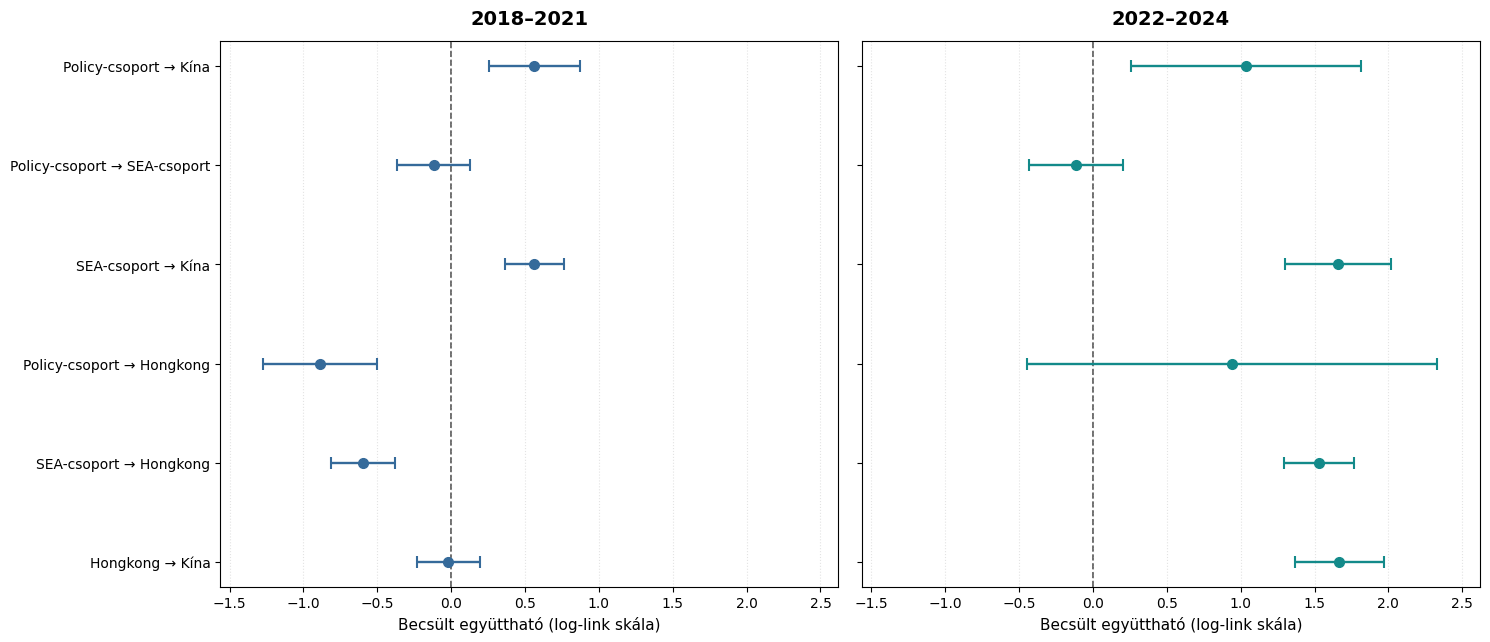

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# ============================================================
# 1. BEÁLLÍTÁSOK
# ============================================================

# Főmodell: HS 848620, Average_Flow függő változóval
model = model13

# Vizsgált útvonalak és a hozzájuk tartozó változónevek
routes = [
    ("Policy-csoport → Kína", "Policy_to_CHN"),
    ("Policy-csoport → SEA-csoport", "Policy_to_SEA"),
    ("SEA-csoport → Kína", "SEA_to_CHN"),
    ("Policy-csoport → Hongkong", "Policy_to_HKG"),
    ("SEA-csoport → Hongkong", "SEA_to_HKG"),
    ("Hongkong → Kína", "HKG_to_CHN"),
]

z_crit = norm.ppf(0.975)  # 95%-os konfidenciaintervallum

# ============================================================
# 2. EGYÜTTHATÓK ÉS KOVARIANCIAMÁTRIX
# ============================================================

params = model.params
cov = model.cov_params().loc[params.index, params.index]

# Ellenőrizzük, hogy minden szükséges interakció szerepel-e
required_terms = []

for _, route_var in routes:
    required_terms.extend([
        f"Sokk18_x_{route_var}",
        f"Sokk22_x_{route_var}",
    ])

missing_terms = [term for term in required_terms if term not in params.index]

if missing_terms:
    raise KeyError(
        "A következő változók nem találhatók a modellben:\n"
        + "\n".join(missing_terms)
    )


# ============================================================
# 3. LINEÁRIS KONTRASZT ÉS KONFIDENCIaintervallum
# ============================================================

def calculate_contrast(terms, label, route_label):
    """
    Egy vagy több regressziós együttható lineáris kombinációját
    számítja ki, a teljes kovarianciamátrix felhasználásával.
    """

    weights = pd.Series(0.0, index=params.index)

    for term in terms:
        weights.loc[term] += 1.0

    estimate = float(weights @ params)

    variance = float(
        weights.to_numpy()
        @ cov.to_numpy()
        @ weights.to_numpy()
    )

    # Kerekítési hibából származó apró negatív varianciát kezeljük
    if variance < -1e-10:
        raise ValueError(
            f"Negatív variancia a következő kontrasztnál: {label}, "
            f"{route_label}. Ellenőrizd a kovarianciamátrixot."
        )

    se = np.sqrt(max(variance, 0.0))

    ci_low = estimate - z_crit * se
    ci_high = estimate + z_crit * se

    return {
        "Periódus": label,
        "Útvonal": route_label,
        "Becsült együttható": estimate,
        "Standard hiba": se,
        "CI alsó határ": ci_low,
        "CI felső határ": ci_high,
    }


# ============================================================
# 4. A KÉT PANELHEZ SZÜKSÉGES EREDMÉNYEK ELŐÁLLÍTÁSA
# ============================================================

results = []

for route_label, route_var in routes:

    beta18 = f"Sokk18_x_{route_var}"
    beta22 = f"Sokk22_x_{route_var}"

    # 2018–2021: a 2018-as periódus együtthatója
    results.append(
        calculate_contrast(
            terms=[beta18],
            label="2018–2021",
            route_label=route_label,
        )
    )

    # 2022–2024: a teljes változás a bázisperiódushoz képest
    # beta18 + beta22
    results.append(
        calculate_contrast(
            terms=[beta18, beta22],
            label="2022–2024",
            route_label=route_label,
        )
    )

plot_df = pd.DataFrame(results)

# Ellenőrzés: a becslések és konfidenciaintervallumok táblázata
display(
    plot_df.round(3)
)


# ============================================================
# 5. ÁBRA ELKÉSZÍTÉSE
# ============================================================

periods = ["2018–2021", "2022–2024"]

period_colors = {
    "2018–2021": "#356A9A",
    "2022–2024": "#138A8A",
}

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 7.5),
    sharey=True,
)

y_positions = np.arange(len(routes))[::-1]

for ax, period in zip(axes, periods):

    subset = (
        plot_df[plot_df["Periódus"] == period]
        .set_index("Útvonal")
        .loc[[route[0] for route in routes]]
        .reset_index()
    )

    estimates = subset["Becsült együttható"].to_numpy()
    ci_low = subset["CI alsó határ"].to_numpy()
    ci_high = subset["CI felső határ"].to_numpy()

    # Aszimmetrikusan megadható hibasávok
    xerr = np.vstack([
        estimates - ci_low,
        ci_high - estimates,
    ])

    ax.errorbar(
        x=estimates,
        y=y_positions,
        xerr=xerr,
        fmt="o",
        color=period_colors[period],
        ecolor=period_colors[period],
        markersize=7,
        elinewidth=1.7,
        capsize=4,
        capthick=1.5,
        linestyle="none",
        zorder=3,
    )

    # Nulla referencia: nincs útvonalspecifikus többletegyüttható
    ax.axvline(
        0,
        color="#555555",
        linestyle="--",
        linewidth=1.2,
        zorder=1,
    )

    ax.set_title(
        period,
        fontsize=14,
        fontweight="bold",
        pad=12,
    )

    ax.set_xlabel(
        "Becsült együttható (log-link skála)",
        fontsize=11,
    )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        [route[0] for route in routes],
        fontsize=10,
    )

    ax.invert_yaxis()
    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.35,
    )

    ax.tick_params(axis="x", labelsize=10)

# Azonos x-tengely a két panelen
all_lows = plot_df["CI alsó határ"].min()
all_highs = plot_df["CI felső határ"].max()
padding = (all_highs - all_lows) * 0.08

x_min = all_lows - padding
x_max = all_highs + padding

for ax in axes:
    ax.set_xlim(x_min, x_max)

fig.tight_layout(rect=[0, 0.06, 1, 0.93])

# Nagy felbontású képfájl és vektoros PDF mentése
fig.savefig(
    "abra1_ppml_fo_modell.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    "abra1_ppml_fo_modell.pdf",
    bbox_inches="tight",
)

plt.show()

Extra hatásként értelmezve

## 4. ábra. Pooled modell együtthatói

,Periódus,Útvonal,Becsült együttható,Standard hiba,CI alsó határ,CI felső határ
0,2018–2021,Policy-csoport → Kína,0.325,0.320,-0.302,0.953
1,2022–2024,Policy-csoport → Kína,0.955,0.371,0.228,1.682
2,2018–2021,Policy-csoport → SEA-csoport,0.169,0.359,-0.535,0.873
3,2022–2024,Policy-csoport → SEA-csoport,-0.199,0.401,-0.984,0.587
4,2018–2021,SEA-csoport → Kína,1.179,0.544,0.113,2.245
5,2022–2024,SEA-csoport → Kína,2.125,0.162,1.809,2.442
6,2018–2021,Policy-csoport → Hongkong,1.396,0.399,0.614,2.178
7,2022–2024,Policy-csoport → Hongkong,4.897,0.542,3.834,5.960
8,2018–2021,SEA-csoport → Hongkong,1.923,1.343,-0.710,4.555
9,2022–2024,SEA-csoport → Hongkong,5.609,1.353,2.957,8.260


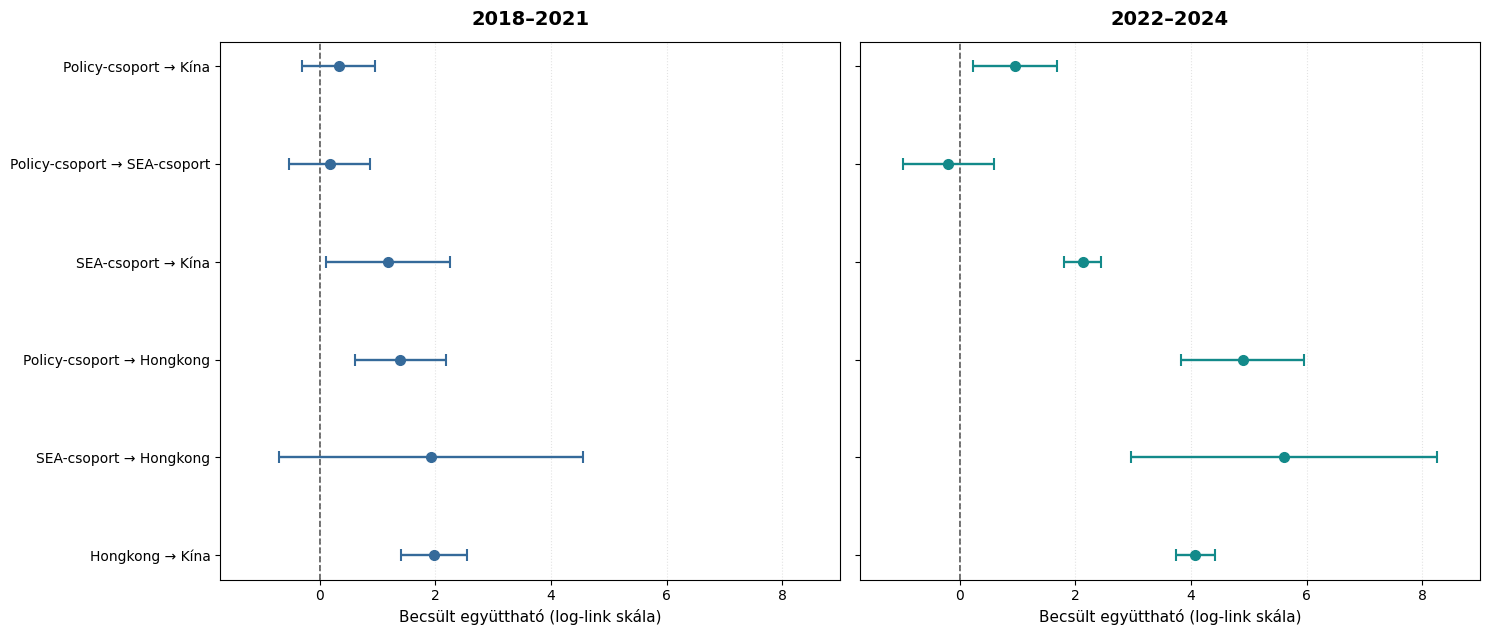

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# ============================================================
# 1. BEÁLLÍTÁSOK
# ============================================================

# Pooled PPML-modell: HS 848620 + HS 848630
model = model33

routes = [
    ("Policy-csoport → Kína", "Policy_to_CHN"),
    ("Policy-csoport → SEA-csoport", "Policy_to_SEA"),
    ("SEA-csoport → Kína", "SEA_to_CHN"),
    ("Policy-csoport → Hongkong", "Policy_to_HKG"),
    ("SEA-csoport → Hongkong", "SEA_to_HKG"),
    ("Hongkong → Kína", "HKG_to_CHN"),
]

z_crit = norm.ppf(0.975)

# ============================================================
# 2. EGYÜTTHATÓK ÉS KOVARIANCIAMÁTRIX
# ============================================================

params = model.params
cov = model.cov_params().loc[params.index, params.index]

# A pooled modellben a Product: interakciók a két termék
# sokkreakciói közötti különbséget mutatják.
required_terms = []

for _, route_var in routes:
    required_terms.extend([
        f"Product:Sokk18_x_{route_var}",
        f"Product:Sokk22_x_{route_var}",
    ])

missing_terms = [
    term for term in required_terms
    if term not in params.index
]

if missing_terms:
    raise KeyError(
        "A következő interakciók nem találhatók a model33 modellben. "
        "Ellenőrizd a modell változóneveit:\n"
        + "\n".join(missing_terms)
    )

# ============================================================
# 3. LINEÁRIS KONTRASZT ÉS 95%-OS KONFIDENCIAINTERVALLUM
# ============================================================

def calculate_contrast(terms, period_label, route_label):
    """
    Egy vagy több Product-interakciós együttható összegét
    számítja ki a teljes kovarianciamátrix felhasználásával.
    """

    weights = pd.Series(0.0, index=params.index)

    for term in terms:
        weights.loc[term] += 1.0

    estimate = float(weights @ params)

    variance = float(
        weights.to_numpy()
        @ cov.to_numpy()
        @ weights.to_numpy()
    )

    if variance < -1e-10:
        raise ValueError(
            f"Negatív variancia: {period_label}, {route_label}"
        )

    se = np.sqrt(max(variance, 0.0))

    return {
        "Periódus": period_label,
        "Útvonal": route_label,
        "Becsült együttható": estimate,
        "Standard hiba": se,
        "CI alsó határ": estimate - z_crit * se,
        "CI felső határ": estimate + z_crit * se,
    }

# ============================================================
# 4. A KÉT PANEL EREDMÉNYEI
# ============================================================

results = []

for route_label, route_var in routes:

    beta18 = f"Product:Sokk18_x_{route_var}"
    beta22 = f"Product:Sokk22_x_{route_var}"

    # 2018–2021: eltérés a két termék útvonalspecifikus
    # változása között a bázisidőszakhoz képest
    results.append(
        calculate_contrast(
            terms=[beta18],
            period_label="2018–2021",
            route_label=route_label,
        )
    )

    # 2022–2024: teljes eltérés a bázisidőszakhoz képest
    # (a 2018-as és a 2022-es interakciós együttható összege)
    results.append(
        calculate_contrast(
            terms=[beta18, beta22],
            period_label="2022–2024",
            route_label=route_label,
        )
    )

plot_df = pd.DataFrame(results)

display(plot_df.round(3))

# ============================================================
# 5. ÁBRA KÉSZÍTÉSE
# ============================================================

periods = ["2018–2021", "2022–2024"]

period_colors = {
    "2018–2021": "#356A9A",
    "2022–2024": "#138A8A",
}

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 7.5),
    sharey=True,
)

# Fordított koordináták: az első útvonal legyen legfelül
y_positions = np.arange(len(routes))[::-1]

for ax, period in zip(axes, periods):

    subset = (
        plot_df[plot_df["Periódus"] == period]
        .set_index("Útvonal")
        .loc[[route[0] for route in routes]]
        .reset_index()
    )

    estimates = subset["Becsült együttható"].to_numpy()
    ci_low = subset["CI alsó határ"].to_numpy()
    ci_high = subset["CI felső határ"].to_numpy()

    xerr = np.vstack([
        estimates - ci_low,
        ci_high - estimates,
    ])

    ax.errorbar(
        x=estimates,
        y=y_positions,
        xerr=xerr,
        fmt="o",
        color=period_colors[period],
        ecolor=period_colors[period],
        markersize=7,
        elinewidth=1.7,
        capsize=4,
        capthick=1.5,
        linestyle="none",
        zorder=3,
    )

    ax.axvline(
        0,
        color="#555555",
        linestyle="--",
        linewidth=1.2,
        zorder=1,
    )

    ax.set_title(
        period,
        fontsize=14,
        fontweight="bold",
        pad=12,
    )

    ax.set_xlabel(
        "Becsült együttható (log-link skála)",
        fontsize=11,
    )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        [route[0] for route in routes],
        fontsize=10,
    )

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.35,
    )

    ax.tick_params(axis="x", labelsize=10)

# Közös x-tengely a két panelen
all_lows = plot_df["CI alsó határ"].min()
all_highs = plot_df["CI felső határ"].max()
padding = (all_highs - all_lows) * 0.08

for ax in axes:
    ax.set_xlim(
        all_lows - padding,
        all_highs + padding,
    )

fig.tight_layout(rect=[0, 0.07, 1, 0.93])

# Mentés
fig.savefig(
    "abra4_ppml_pooled_termekkulonbseg.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    "abra4_ppml_pooled_termekkulonbseg.pdf",
    bbox_inches="tight",
)

plt.show()

## Függelék regressziós outputok összegzése

In [ ]:
import numpy as np
import pandas as pd

# ==================================================
# A1. FŐMODELL – TELJES BECSLÉSI EREDMÉNYEK
# ==================================================

model = model13

# Becslések és dyád szerint klaszterezett
# kovarianciamátrixból számított 95%-os CI
ci = np.asarray(model.conf_int(alpha=0.05))

results = pd.DataFrame({
    "Változó": model.params.index,
    "Becsült együttható": np.asarray(model.params),
    "Robusztus standard hiba": np.asarray(model.bse),
    "z-statisztika": np.asarray(model.params) / np.asarray(model.bse),
    "p-érték": np.asarray(model.pvalues),
    "95% CI alsó határ": ci[:, 0],
    "95% CI felső határ": ci[:, 1],
})

# A modell főbb jellemzői
model_info = pd.DataFrame({
    "Mutató": [
        "Modell",
        "Függő változó",
        "Megfigyelések száma",
        "Dyádok száma",
        "Becslési eljárás",
        "Standard hibák",
        "Log-likelihood",
        "AIC",
        "Deviance",
        "Null deviance",
        "Modell szabadságfoka",
        "Reziduális szabadságfok",
    ],
    "Érték": [
        "Főmodell – HS 848620",
        model.model.endog_names,
        int(model.nobs),
        df_lito["Dyad"].nunique(),
        "Poisson GLM (PPML), log-link",
        "Dyád szerint klaszterezett",
        model.llf,
        model.aic,
        model.deviance,
        model.null_deviance,
        model.df_model,
        model.df_resid,
    ]
})

# Megjelenítéshez és exporthoz: legfeljebb 3 tizedesjegy
results_export = results.round(3)

# A nagyon kis p-értékeket ne kerekítsük 0.000-ra
results_export["p-érték"] = results["p-érték"].apply(
    lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"
)

# Modellmutatók kerekítése, a szövegek és egész számok megtartásával
model_info_export = model_info.copy()
model_info_export["Érték"] = model_info_export["Érték"].apply(
    lambda x: round(x, 3)
    if isinstance(x, (float, np.floating))
    else x
)

# Export két munkalapra
# file_path = "fuggelek_A1_fo_modell.xlsx"

# with pd.ExcelWriter(file_path, engine="openpyxl") as writer:
#     results_export.to_excel(
#         writer, sheet_name="Egyutthatok", index=False
#     )
#     model_info_export.to_excel(
#         writer, sheet_name="Modelladatok", index=False
#     )

#     # Alapvető formázás
#     for ws in writer.book.worksheets:
#         ws.freeze_panes = "A2"
#         ws.auto_filter.ref = ws.dimensions

#         for column in ws.columns:
#             max_length = max(
#                 len(str(cell.value)) if cell.value is not None else 0
#                 for cell in column
#             )
#             ws.column_dimensions[
#                 column[0].column_letter
#             ].width = min(max(max_length + 2, 14), 32)

# Eredmények megjelenítése a notebookban
display(results_export)
display(model_info_export)

# print(f"Elmentve: {file_path}")

,Változó,Becsült együttható,Robusztus standard hiba,z-statisztika,p-érték,95% CI alsó határ,95% CI felső határ
0,Intercept,-60.351,6.399,-9.431,<0.001,-72.893,-47.810
1,C(Year)[T.2016],0.113,0.074,1.523,0.128,-0.032,0.259
2,C(Year)[T.2017],0.165,0.121,1.368,0.171,-0.071,0.401
3,C(Year)[T.2018],-0.013,0.123,-0.102,0.919,-0.254,0.229
4,C(Year)[T.2019],-0.034,0.119,-0.284,0.776,-0.267,0.199
5,C(Year)[T.2020],0.184,0.097,1.888,0.059,-0.007,0.375
6,C(Year)[T.2021],0.020,0.122,0.167,0.868,-0.219,0.259
7,C(Year)[T.2022],-0.327,0.137,-2.388,0.017,-0.595,-0.059
8,C(Year)[T.2023],-0.298,0.144,-2.062,0.039,-0.581,-0.015
9,C(Year)[T.2024],-0.397,0.180,-2.212,0.027,-0.749,-0.045


,Mutató,Érték
0,Modell,Főmodell – HS 848620
1,Függő változó,Average_Flow
2,Megfigyelések száma,12600
3,Dyádok száma,1260
4,Becslési eljárás,"Poisson GLM (PPML), log-link"
5,Standard hibák,Dyád szerint klaszterezett
6,Log-likelihood,-691004098927.266968
7,AIC,1382008197930.532959
8,Deviance,1382008087367.297119
9,Null deviance,3737989344989.359863


In [ ]:
import numpy as np
import pandas as pd

# ==================================================
# A2. POOLED MODELL – TELJES BECSLÉSI EREDMÉNYEK
# ==================================================

model = model33

# Becslések és dyád szerint klaszterezett
# kovarianciamátrixból számított 95%-os CI
ci = np.asarray(model.conf_int(alpha=0.05))

results = pd.DataFrame({
    "Változó": model.params.index,
    "Becsült együttható": np.asarray(model.params),
    "Robusztus standard hiba": np.asarray(model.bse),
    "z-statisztika": np.asarray(model.params) / np.asarray(model.bse),
    "p-érték": np.asarray(model.pvalues),
    "95% CI alsó határ": ci[:, 0],
    "95% CI felső határ": ci[:, 1],
})

# A modell főbb jellemzői
model_info = pd.DataFrame({
    "Mutató": [
        "Modell",
        "Függő változó",
        "Megfigyelések száma",
        "Dyádok száma",
        "Becslési eljárás",
        "Standard hibák",
        "Termékkód 1",
        "Termékkód 0 (referencia)",
        "Log-likelihood",
        "AIC",
        "Deviance",
        "Null deviance",
        "Modell szabadságfoka",
        "Reziduális szabadságfok",
    ],
    "Érték": [
        "Pooled modell – HS 848620 és HS 848630",
        model.model.endog_names,
        int(model.nobs),
        df_pool["Dyad"].nunique(),
        "Poisson GLM (PPML), log-link",
        "Dyád szerint klaszterezett",
        848620,
        848630,
        model.llf,
        model.aic,
        model.deviance,
        model.null_deviance,
        model.df_model,
        model.df_resid,
    ]
})

# Megjelenítéshez és exporthoz: legfeljebb 3 tizedesjegy
results_export = results.round(3)

# A nagyon kis p-értékeket ne kerekítsük 0.000-ra
results_export["p-érték"] = results["p-érték"].apply(
    lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"
)

# Modellmutatók kerekítése, a szövegek és egész számok megtartásával
model_info_export = model_info.copy()
model_info_export["Érték"] = model_info_export["Érték"].apply(
    lambda x: round(x, 3)
    if isinstance(x, (float, np.floating))
    else x
)

# Export két munkalapra
# file_path = "fuggelek_A2_pooled_modell.xlsx"

# with pd.ExcelWriter(file_path, engine="openpyxl") as writer:
#     results_export.to_excel(
#         writer, sheet_name="Egyutthatok", index=False
#     )
#     model_info_export.to_excel(
#         writer, sheet_name="Modelladatok", index=False
#     )

#     # Alapvető formázás
#     for ws in writer.book.worksheets:
#         ws.freeze_panes = "A2"
#         ws.auto_filter.ref = ws.dimensions

#         for column in ws.columns:
#             max_length = max(
#                 len(str(cell.value)) if cell.value is not None else 0
#                 for cell in column
#             )
#             ws.column_dimensions[
#                 column[0].column_letter
#             ].width = min(max(max_length + 2, 14), 32)

# Eredmények megjelenítése a notebookban
display(results_export)
display(model_info_export)

# print(f"Elmentve: {file_path}")

,Változó,Becsült együttható,Robusztus standard hiba,z-statisztika,p-érték,95% CI alsó határ,95% CI felső határ
0,Intercept,-61.145,6.406,-9.544,<0.001,-73.701,-48.588
1,C(Year)[T.2016],0.276,0.131,2.107,0.035,0.019,0.532
2,C(Year)[T.2017],0.415,0.165,2.517,0.012,0.092,0.738
3,C(Year)[T.2018],0.223,0.215,1.038,0.299,-0.198,0.645
4,C(Year)[T.2019],-0.126,0.204,-0.617,0.537,-0.526,0.274
...,...,...,...,...,...,...,...
61,Product:Sokk22_x_Policy_to_SEA,-0.368,0.461,-0.798,0.425,-1.270,0.535
62,Product:Sokk22_x_SEA_to_CHN,0.946,0.594,1.593,0.111,-0.218,2.110
63,Product:Sokk22_x_Policy_to_HKG,3.501,0.351,9.962,<0.001,2.812,4.190
64,Product:Sokk22_x_SEA_to_HKG,3.686,1.255,2.938,0.003,1.227,6.145


,Mutató,Érték
0,Modell,Pooled modell – HS 848620 és HS 848630
1,Függő változó,Average_Flow
2,Megfigyelések száma,25200
3,Dyádok száma,1260
4,Becslési eljárás,"Poisson GLM (PPML), log-link"
5,Standard hibák,Dyád szerint klaszterezett
6,Termékkód 1,848620
7,Termékkód 0 (referencia),848630
8,Log-likelihood,-815106223224.178955
9,AIC,1630212446580.356934


## Tükörstatisztikákból adódó eltérések ellenőrzése

In [23]:
# Tükörstatisztikák ellenőrzése a két hongkongi útvonalon

for nev, utvonal in [
    ("Hongkong → Kína", "HKG_to_CHN"),
    ("Policy-csoport → Hongkong", "Policy_to_HKG")
]:
    print(f"\n{nev}")

    adatok = df_lito[df_lito[utvonal] == 1]

    eredmeny = (
        adatok.groupby("Year")
        .agg(
            Jelentett_export=("Reported_Export", "sum"),
            Jelentett_import=("Reported_Import", "sum")
        )
        .reset_index()
    )

    eredmeny["Export / import arány"] = (
        eredmeny["Jelentett_export"]
        / eredmeny["Jelentett_import"].replace(0, np.nan)
    )

    eredmeny["Export - import különbség"] = (
        eredmeny["Jelentett_export"]
        - eredmeny["Jelentett_import"]
    )

    display(eredmeny.round(2))

    print("Teljes időszak:")
    print("Jelentett export összesen:",
          round(eredmeny["Jelentett_export"].sum(), 2))
    print("Jelentett import összesen:",
          round(eredmeny["Jelentett_import"].sum(), 2))


Hongkong → Kína


,Year,Jelentett_export,Jelentett_import,Export / import arány,Export - import különbség
0,2015,5.989485e+07,20526713.0,2.92,3.936814e+07
1,2016,5.986891e+07,8385599.0,7.14,5.148331e+07
2,2017,6.059174e+07,2749868.0,22.03,5.784187e+07
3,2018,4.859649e+07,6764250.0,7.18,4.183224e+07
4,2019,1.398464e+08,3483738.0,40.14,1.363626e+08
5,2020,2.876350e+08,1831125.0,157.08,2.858039e+08
6,2021,6.959300e+08,2821585.0,246.65,6.931084e+08
7,2022,1.215834e+09,1856462.0,654.92,1.213978e+09
8,2023,1.147791e+09,2855239.0,401.99,1.144936e+09
9,2024,1.999162e+09,4750441.0,420.84,1.994412e+09


Teljes időszak:
Jelentett export összesen: 5715150670.21
Jelentett import összesen: 56025020.0

Policy-csoport → Hongkong


,Year,Jelentett_export,Jelentett_import,Export / import arány,Export - import különbség
0,2015,26386439.85,1.192501e+07,2.21,1.446143e+07
1,2016,29110750.29,1.646512e+07,1.77,1.264563e+07
2,2017,33324440.62,2.566151e+07,1.30,7.662930e+06
3,2018,26399197.51,1.341421e+07,1.97,1.298499e+07
4,2019,37168251.75,4.415192e+07,0.84,-6.983666e+06
5,2020,34437191.02,2.474109e+07,1.39,9.696100e+06
6,2021,56171802.20,5.449391e+07,1.03,1.677890e+06
7,2022,84745230.35,9.130489e+07,0.93,-6.559659e+06
8,2023,60278247.41,2.779312e+08,0.22,-2.176530e+08
9,2024,43147801.17,7.930798e+08,0.05,-7.499320e+08


Teljes időszak:
Jelentett export összesen: 431169352.16
Jelentett import összesen: 1353168705.97
